# K-means Clustering of Retail Bricks
**Dataset:** `Dummy_Retail_Profits_Unpivoted.csv` – 1,097 bricks × 7 packs × 60 months (Aug-2021 → Jul-2026), three companies, eight Australian states/territories.

**Objective:** group bricks into a small number of behaviourally distinct segments (size, momentum, stability, competitive mix) that can be used for coverage, targeting and resourcing decisions.

**Approach:** clean → EDA → brick-level feature engineering → scaling → clustering-tendency check → choose *k* (elbow, silhouette, Calinski-Harabasz, Davies-Bouldin, bootstrap stability) → fit → profile → validate against state (an input the model never saw) → save artefacts.

Each code cell is followed by a short **Insight** note interpreting its output.

## 1. Setup

In [1]:
%matplotlib inline
import warnings, json, os
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.stats import chi2_contingency

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 90
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 200)

# Data location: current folder first, then the Copilot upload folder
CANDIDATES = ["Dummy_Retail_Profits_Unpivoted.csv", "/mnt/user-data/uploads/Dummy_Retail_Profits_Unpivoted.csv"]
DATA_PATH = next(p for p in CANDIDATES if os.path.exists(p))
os.makedirs("artifacts", exist_ok=True)
print("Using:", DATA_PATH)

Using: /mnt/user-data/uploads/Dummy_Retail_Profits_Unpivoted.csv


## 2. Load the data
The file is an *unpivoted* (long) retail sell-out extract: one row per **Brick × Pack × Month**. We inspect structure and data types before touching anything.

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
display(df.head())
print(df.dtypes.to_string())
print("\nUnique values -> bricks:", df["Brick Name"].nunique(), "| states:", df["State"].nunique(),
      "| companies:", df["Company"].nunique(), "| packs:", df["Pack"].nunique(), "| months:", df["Month"].nunique())

Shape: (460740, 8)


,Brick Name,State,Company,Pack,Month,Year,MonthNum,Units
0,Brick 0001,QLD,Company A,Product A,Aug-2021,2021,8,10
1,Brick 0001,QLD,Company A,Product A,Sep-2021,2021,9,10
2,Brick 0001,QLD,Company A,Product A,Oct-2021,2021,10,13
3,Brick 0001,QLD,Company A,Product A,Nov-2021,2021,11,10
4,Brick 0001,QLD,Company A,Product A,Dec-2021,2021,12,12


Brick Name    object
State         object
Company       object
Pack          object
Month         object
Year           int64
MonthNum       int64
Units         object

Unique values -> bricks: 1097 | states: 8 | companies: 3 | packs: 7 | months: 60


> **Insight —** The file has 460,740 rows = 1,097 bricks × 7 packs × 60 months, so it is a complete panel. `Units` was read as text (object) because missing sales are stored as `-`; this must be fixed before any maths.

## 3. Data cleaning & validation
`Units` is read as text because missing sales are written as `"-"`. In sell-out data a dash means *no units sold that month*, so it is converted to **0** (not dropped). We then verify the panel is complete and consistent.

In [3]:
dash_n = (df["Units"] == "-").sum()
print(f"'-' entries: {dash_n:,} ({dash_n/len(df):.1%} of rows) -> converted to 0")
df["Units"] = pd.to_numeric(df["Units"].replace("-", 0)).astype(int)
df["Date"] = pd.to_datetime(df["Month"], format="%b-%Y")

n_b, n_p, n_m = df["Brick Name"].nunique(), df["Pack"].nunique(), df["Date"].nunique()
checks = pd.Series({
    "Date range": f"{df['Date'].min():%b-%Y} to {df['Date'].max():%b-%Y}",
    "Rows (actual)": len(df),
    "Rows (expected = bricks x packs x months)": n_b * n_p * n_m,
    "Duplicate Brick-Pack-Month rows": int(df.duplicated(["Brick Name", "Pack", "Date"]).sum()),
    "Negative unit values": int((df["Units"] < 0).sum()),
    "Bricks mapped to >1 state": int((df.groupby("Brick Name")["State"].nunique() > 1).sum()),
    "Missing values (any column)": int(df.isna().sum().sum()),
})
display(checks.to_frame("Check"))

'-' entries: 91,234 (19.8% of rows) -> converted to 0


,Check
Date range,Aug-2021 to Jul-2026
Rows (actual),460740
Rows (expected = bricks x packs x months),460740
Duplicate Brick-Pack-Month rows,0
Negative unit values,0
Bricks mapped to >1 state,0
Missing values (any column),0


> **Insight —** 19.8 % of rows (91,234) are dashes, now treated as zero sales. The panel is complete (actual rows = expected rows) with no duplicates, negatives or missing values, and every brick maps to exactly one state – the data is clean enough to model without row removal.

## 4. Exploratory data analysis
Before engineering features we look at how units are distributed across packs, companies, states and time.

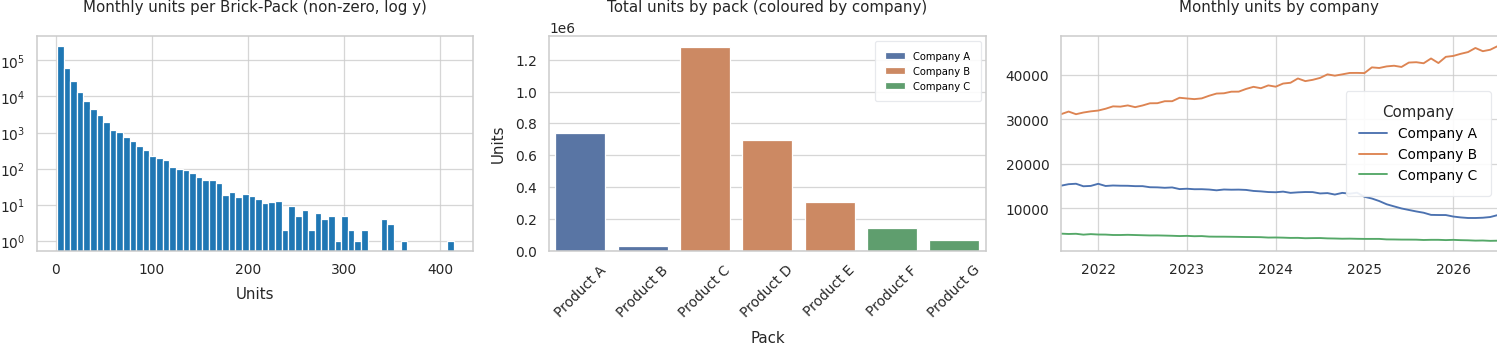

,Company,Pack,Units,ZeroShare
0,Company A,Product A,"738,054",0.8%
1,Company A,Product B,"27,002",80.9%
2,Company B,Product C,"1,282,906",0.1%
3,Company B,Product D,"696,127",0.6%
4,Company B,Product E,"306,582",3.8%
5,Company C,Product F,"140,732",15.5%
6,Company C,Product G,"67,832",36.8%


In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
nz = df.loc[df["Units"] > 0, "Units"]
ax[0].hist(nz, bins=60, color="#1f77b4"); ax[0].set_yscale("log")
ax[0].set_title("Monthly units per Brick-Pack (non-zero, log y)"); ax[0].set_xlabel("Units")

pack_tbl = df.groupby(["Company", "Pack"]).agg(Units=("Units", "sum"), ZeroShare=("Units", lambda s: (s == 0).mean())).reset_index()
sns.barplot(data=pack_tbl, x="Pack", y="Units", hue="Company", dodge=False, ax=ax[1])
ax[1].set_title("Total units by pack (coloured by company)"); ax[1].tick_params(axis="x", rotation=45); ax[1].legend(loc="upper right", fontsize=8)

monthly = df.groupby(["Date", "Company"])["Units"].sum().unstack()
monthly.plot(ax=ax[2]); ax[2].set_title("Monthly units by company"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

display(pack_tbl.assign(ZeroShare=lambda d: d["ZeroShare"].map("{:.1%}".format), Units=lambda d: d["Units"].map("{:,}".format)))

> **Insight —** Volume is heavily right-skewed (most brick-pack-months are under 10 units, max 414). Product C (Company B) is the biggest pack at ~1.28 M units; Product B is almost dormant (80.9 % zero months) and Product G is intermittent (36.8 %). Company B has grown steadily while Company A has fallen since 2025 and Company C is drifting down.

In [5]:
state_tbl = df.groupby("State").agg(Bricks=("Brick Name", "nunique"), Units=("Units", "sum"))
state_tbl["Share of units"] = (state_tbl["Units"] / state_tbl["Units"].sum()).map("{:.1%}".format)
state_tbl["Units per brick"] = (state_tbl["Units"] / state_tbl["Bricks"]).round(0)
display(state_tbl.sort_values("Units", ascending=False))

tot = df.groupby("Date")["Units"].sum()
yoy = tot.rolling(12).sum().pct_change(12).dropna()
print(f"Total units, last 12 months: {tot.iloc[-12:].sum():,} | previous 12 months: {tot.iloc[-24:-12].sum():,} | change: {tot.iloc[-12:].sum()/tot.iloc[-24:-12].sum()-1:+.1%}")

,Bricks,Units,Share of units,Units per brick
State,,,,
NSW,320,937467,28.8%,2930.0
VIC,260,858419,26.3%,3302.0
QLD,204,589105,18.1%,2888.0
WA,127,341727,10.5%,2691.0
SA,90,267171,8.2%,2969.0
ACT,58,172894,5.3%,2981.0
TAS,31,66669,2.0%,2151.0
NT,7,25783,0.8%,3683.0


Total units, last 12 months: 668,191 | previous 12 months: 675,278 | change: -1.0%


> **Insight —** NSW (320 bricks, 28.8 % of units) and VIC (260 bricks, 26.3 %) dominate; VIC has the highest units per brick (3,302), NT is tiny (7 bricks). Total volume in the last 12 months is 668,191 units, −1.0 % vs the prior 12 months – a flat market, so growth differences between bricks are the interesting signal.

## 5. Feature engineering (Brick level)
Clustering needs **one row per brick**. We collapse the 60-month panel into behavioural features that describe *how big*, *how fast-growing*, *how stable* and *what mix* each brick is. **State is deliberately excluded** from the model so that it can later be used as an independent check of the clusters.

| Feature | Definition | Why it matters |
|---|---|---|
| `Log_L12M` | log(1 + units, last 12 months Aug-25 to Jul-26) | Size / market potential (log tames skew) |
| `YoY_Growth` | L12M vs previous 12M, clipped to [-100%, +200%] | Momentum |
| `Trend_Slope` | OLS slope over 60 months ÷ mean monthly units | Long-run structural trend |
| `CV` | Std ÷ mean of monthly units | Volume stability / intermittency |
| `Seasonality` | Peak calendar-month average ÷ overall monthly average | Seasonal concentration |
| `Share_CompA/B/C` | Share of L12M units by company | Competitive mix |

In [6]:
months = np.sort(df["Date"].unique())
l12, p12 = months[-12:], months[-24:-12]
print("L12M window:", pd.Timestamp(l12[0]).strftime("%b-%Y"), "to", pd.Timestamp(l12[-1]).strftime("%b-%Y"),
      "| P12M window:", pd.Timestamp(p12[0]).strftime("%b-%Y"), "to", pd.Timestamp(p12[-1]).strftime("%b-%Y"))

brick_month = df.groupby(["Brick Name", "Date"])["Units"].sum().unstack()          # 1097 x 60
comp_l12 = df[df["Date"].isin(l12)].pivot_table(index="Brick Name", columns="Company", values="Units", aggfunc="sum", fill_value=0)

F = pd.DataFrame(index=brick_month.index)
F["L12M"] = brick_month[l12].sum(axis=1)
F["P12M"] = brick_month[p12].sum(axis=1)
F["Log_L12M"] = np.log1p(F["L12M"])
F["YoY_Growth"] = ((F["L12M"] - F["P12M"]) / F["P12M"]).clip(-1, 2)

t = np.arange(brick_month.shape[1])
F["Trend_Slope"] = np.array([np.polyfit(t, r, 1)[0] for r in brick_month.values]) / brick_month.mean(axis=1).values
F["CV"] = brick_month.std(axis=1) / brick_month.mean(axis=1)
F["Zero_Month_Pct"] = (brick_month == 0).mean(axis=1)

moy = brick_month.copy(); moy.columns = pd.DatetimeIndex(moy.columns).month
moy = moy.T.groupby(level=0).mean().T
F["Seasonality"] = moy.max(axis=1) / moy.mean(axis=1)

for c in ["Company A", "Company B", "Company C"]:
    F["Share_Comp" + c[-1]] = comp_l12[c] / comp_l12.sum(axis=1)
F["Pack_Breadth"] = (df[df["Date"].isin(l12)].groupby(["Brick Name", "Pack"])["Units"].sum().gt(0)
                     .groupby("Brick Name").sum())
F["State"] = df.drop_duplicates("Brick Name").set_index("Brick Name")["State"]

print("Feature table:", F.shape)
display(F.describe().T.round(3))

L12M window: Aug-2025 to Jul-2026 | P12M window: Aug-2024 to Jul-2025
Feature table: (1097, 13)


,count,mean,std,min,25%,50%,75%,max
L12M,1097.0,609.108,665.614,11.000,230.000,422.000,734.000,7513.000
P12M,1097.0,615.568,672.848,8.000,233.000,423.000,743.000,8006.000
Log_L12M,1097.0,5.998,0.934,2.485,5.442,6.047,6.600,8.925
YoY_Growth,1097.0,-0.011,0.067,-0.257,-0.056,-0.012,0.033,0.375
Trend_Slope,1097.0,0.002,0.001,-0.003,0.001,0.002,0.003,0.022
CV,1097.0,0.164,0.035,0.108,0.149,0.160,0.172,1.027
Zero_Month_Pct,1097.0,0.000,0.014,0.000,0.000,0.000,0.000,0.467
Seasonality,1097.0,1.137,0.047,1.043,1.107,1.130,1.160,1.667
Share_CompA,1097.0,0.148,0.017,0.000,0.141,0.149,0.158,0.193
Share_CompB,1097.0,0.807,0.028,0.750,0.791,0.802,0.814,1.000


> **Insight —** The 1,097-row feature table is strongly skewed: L12M median 422 vs mean 609 and max 7,513 units. YoY growth averages −1.1 % (range −25.7 % to +37.5 %); company mix is ~81 % B / ~15 % A / ~4 % C. A few bricks have extreme CV (max 1.03) and 92 bricks have no Company C sales at all – these will behave as outliers.

### 5.1 Feature selection
We check collinearity among candidate features and drop redundant ones so that no single concept is double-weighted in a distance-based model.

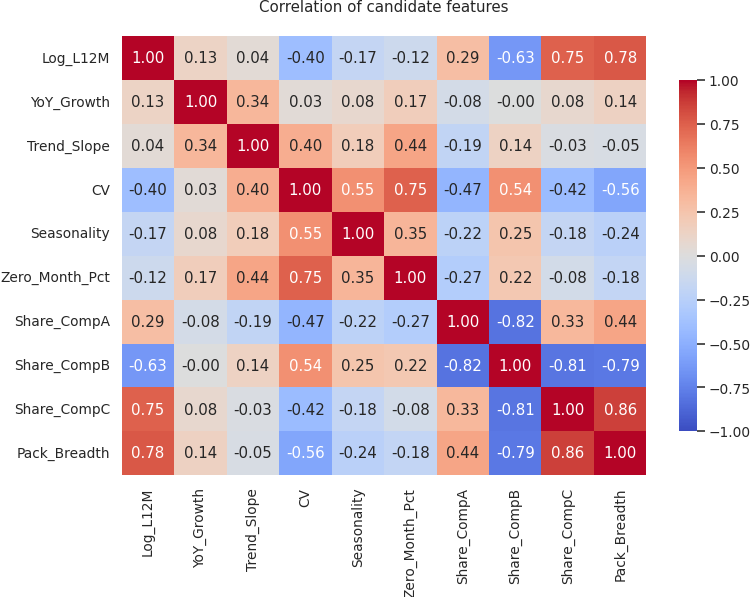

Pairs with |r| >= 0.70:
Share_CompC  Pack_Breadth      0.86
Log_L12M     Pack_Breadth      0.78
CV           Zero_Month_Pct    0.75
Log_L12M     Share_CompC       0.75
Share_CompB  Pack_Breadth     -0.79
             Share_CompC      -0.81
Share_CompA  Share_CompB      -0.82


In [7]:
cand = ["Log_L12M", "YoY_Growth", "Trend_Slope", "CV", "Seasonality", "Zero_Month_Pct",
        "Share_CompA", "Share_CompB", "Share_CompC", "Pack_Breadth"]
corr = F[cand].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1, cbar_kws={"shrink": .8})
plt.title("Correlation of candidate features"); plt.tight_layout(); plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
print("Pairs with |r| >= 0.70:"); print(pairs[pairs.abs() >= 0.70].sort_values(ascending=False).round(2).to_string())

> **Insight —** Size and range travel together: `Log_L12M` correlates 0.78 with `Pack_Breadth` and 0.75 with `Share_CompC` (big bricks stock the full range); volatility (`CV`) falls with size (r≈−0.48). The three company shares sum to 1 (A vs B r = −0.82), so one must go. `Pack_Breadth` and `Zero_Month_Pct` are redundant and are dropped.

In [8]:
FEATURES = ["Log_L12M", "YoY_Growth", "Trend_Slope", "CV", "Seasonality", "Share_CompA", "Share_CompC"]
dropped = {"Pack_Breadth": "r~0.78 with Log_L12M and 0.86 with Share_CompC (size / range proxy)", "Zero_Month_Pct": "r~0.75 with CV; near-constant (almost no zero months)",
           "Share_CompB": "reference category - the three shares sum to 1"}
print("Model features:", FEATURES); print("Dropped:", dropped)

Model features: ['Log_L12M', 'YoY_Growth', 'Trend_Slope', 'CV', 'Seasonality', 'Share_CompA', 'Share_CompC']
Dropped: {'Pack_Breadth': 'r~0.78 with Log_L12M and 0.86 with Share_CompC (size / range proxy)', 'Zero_Month_Pct': 'r~0.75 with CV; near-constant (almost no zero months)', 'Share_CompB': 'reference category - the three shares sum to 1'}


## 6. Pre-processing
Both K-means and DBSCAN are **distance-based**, so features must be on a comparable scale and extreme values must not dominate. Steps: (1) winsorise heavy-tailed features at the 1st/99th percentile, (2) standardise to mean 0 / SD 1.

In [9]:
X = F[FEATURES].copy()
skew_before = X.skew()
for col in ["CV", "Trend_Slope", "Seasonality"]:
    lo, hi = X[col].quantile([.01, .99]); X[col] = X[col].clip(lo, hi)
scaler = StandardScaler()
Z = pd.DataFrame(scaler.fit_transform(X), index=X.index, columns=FEATURES)
display(pd.DataFrame({"skew_before": skew_before, "skew_after_winsorise": X.skew(), "scaled_mean": Z.mean(), "scaled_std": Z.std()}).round(3))
Z.to_csv("artifacts/brick_features_scaled.csv"); F.to_csv("artifacts/brick_features_raw.csv")

,skew_before,skew_after_winsorise,scaled_mean,scaled_std
Log_L12M,-0.194,-0.194,-0.0,1.0
YoY_Growth,0.118,0.118,-0.0,1.0
Trend_Slope,2.972,0.072,-0.0,1.0
CV,14.063,1.342,-0.0,1.0
Seasonality,1.928,0.641,-0.0,1.0
Share_CompA,-3.294,-3.294,0.0,1.0
Share_CompC,-1.623,-1.623,-0.0,1.0


> **Insight —** Winsorising removed the heavy tails: skew falls from 14.1 → 1.3 for `CV`, 3.0 → 0.07 for `Trend_Slope` and 1.9 → 0.6 for `Seasonality`. After scaling all seven features have mean 0 / SD 1, so no feature dominates the distance. `Share_CompA` stays left-skewed (−3.3) because five bricks have zero Company A – we leave them as genuine outliers.

## 7. Clustering tendency & dimensionality
Two sanity checks before clustering: (a) the **Hopkins statistic** – does the data contain non-random structure (≈0.5 = uniform noise, →1 = clusterable)? (b) **PCA** – how many latent dimensions does the feature space really have?

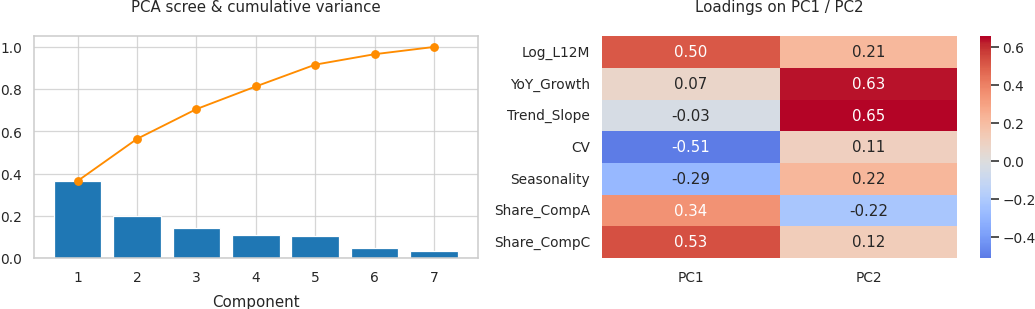

Hopkins statistic: 0.811
Cumulative variance: [0.366 0.565 0.706 0.813 0.916 0.966 1.   ]


In [10]:
def hopkins(Zv, m=None, seed=RANDOM_STATE, reps=10):
    Zv = np.asarray(Zv); n, d = Zv.shape; m = m or int(0.1 * n)
    r = np.random.default_rng(seed); nn = NearestNeighbors(n_neighbors=2).fit(Zv); out = []
    for _ in range(reps):
        idx = r.choice(n, m, replace=False)
        w = nn.kneighbors(Zv[idx], 2)[0][:, 1]
        u = nn.kneighbors(r.uniform(Zv.min(0), Zv.max(0), (m, d)), 1)[0][:, 0]
        out.append(u.sum() / (u.sum() + w.sum()))
    return float(np.mean(out))

H = hopkins(Z)
pca_full = PCA().fit(Z)
cum = np.cumsum(pca_full.explained_variance_ratio_)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(range(1, len(cum) + 1), pca_full.explained_variance_ratio_, color="#1f77b4"); ax[0].plot(range(1, len(cum) + 1), cum, "o-", color="darkorange")
ax[0].set_title("PCA scree & cumulative variance"); ax[0].set_xlabel("Component")
load = pd.DataFrame(pca_full.components_[:2].T, index=FEATURES, columns=["PC1", "PC2"])
sns.heatmap(load, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax[1]); ax[1].set_title("Loadings on PC1 / PC2")
plt.tight_layout(); plt.show()
print(f"Hopkins statistic: {H:.3f}")
print("Cumulative variance:", np.round(cum, 3))

> **Insight —** Hopkins = 0.81 (well above 0.5), so the data has real non-random structure. PC1 (37 %) is a size/range/stability axis (Log_L12M, Share_CompC up; CV down) and PC2 (20 %) is a momentum axis (YoY growth, trend slope). Two components explain only 57 % of variance (five are needed for 92 %), so 2-D plots will show some overlap that is a projection effect.

## 8. Choosing *k*
We fit K-means (k-means++ init, 20 restarts) for k = 2…10 and compare four internal metrics:
- **Inertia** (within-cluster SSE, elbow) – lower is better, always falls with k.
- **Silhouette** (–1…1) – cohesion vs separation, higher is better.
- **Calinski-Harabasz** – between/within variance ratio, higher is better.
- **Davies-Bouldin** – average cluster similarity, lower is better.

,Inertia,Silhouette,Calinski_Harabasz,Davies_Bouldin,Smallest_cluster
k,,,,,
2,5797.205,0.402,355.441,1.308,155
3,5036.045,0.161,287.071,1.759,137
4,4544.771,0.169,251.257,1.568,16
5,4133.399,0.156,234.177,1.557,16
6,3871.732,0.157,214.567,1.591,15
7,3638.579,0.140,201.730,1.658,15
8,3458.664,0.139,189.832,1.610,15
9,3294.308,0.139,181.015,1.567,15
10,3158.327,0.141,172.875,1.529,12


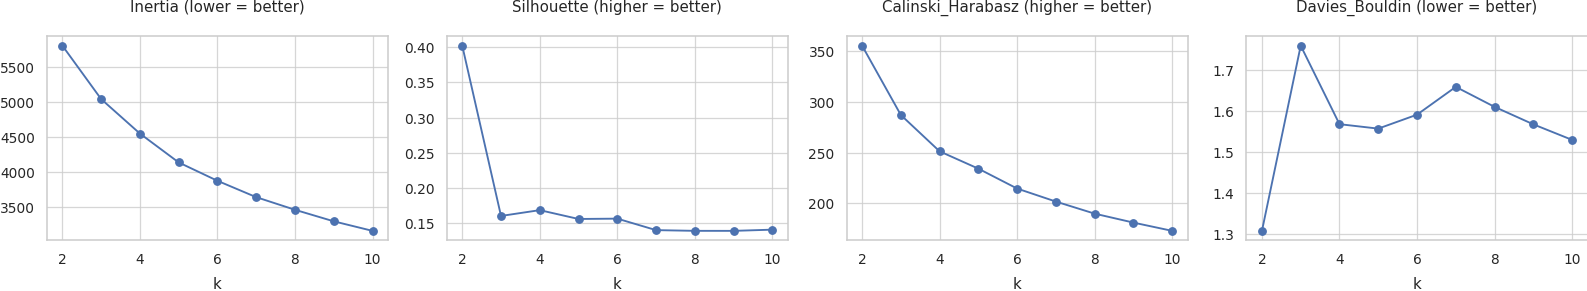

In [11]:
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Z)
    rows.append({"k": k, "Inertia": km.inertia_, "Silhouette": silhouette_score(Z, km.labels_),
                 "Calinski_Harabasz": calinski_harabasz_score(Z, km.labels_),
                 "Davies_Bouldin": davies_bouldin_score(Z, km.labels_),
                 "Smallest_cluster": int(np.bincount(km.labels_).min())})
ksel = pd.DataFrame(rows).set_index("k")
display(ksel.round(3))

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for a, (col, good) in zip(ax, [("Inertia", "lower"), ("Silhouette", "higher"), ("Calinski_Harabasz", "higher"), ("Davies_Bouldin", "lower")]):
    a.plot(ksel.index, ksel[col], "o-"); a.set_title(f"{col} ({good} = better)"); a.set_xlabel("k")
plt.tight_layout(); plt.show()

> **Insight —** Silhouette peaks at k = 2 (0.402) and then drops to ~0.14–0.17 for every k ≥ 3: the main mass of bricks is one continuous cloud with a small, clearly different tail. Inertia falls smoothly with no sharp elbow, and from k = 4 upward the smallest cluster is only 12–16 bricks.

### 8.1 Stability check
A good *k* should give the same segments when the data is perturbed. For each k we draw 25 random 80 % subsamples, re-fit K-means and compare the labels with the full-data solution on the same bricks using the **Adjusted Rand Index** (1 = identical).

,ARI_mean,ARI_std
k,,
2,0.983,0.023
3,0.918,0.029
4,0.800,0.200
5,0.750,0.165
6,0.656,0.194
7,0.585,0.191
8,0.528,0.167


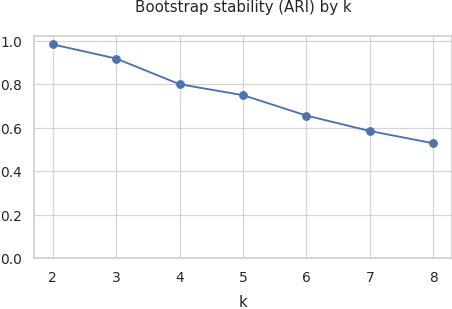

In [12]:
def kmeans_stability(Zv, k, B=25, frac=0.8):
    ref = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(Zv).labels_
    out = []
    for b in range(B):
        idx = rng.choice(len(Zv), int(frac * len(Zv)), replace=False)
        lab = KMeans(n_clusters=k, n_init=10, random_state=b).fit(Zv.iloc[idx]).labels_
        out.append(adjusted_rand_score(ref[idx], lab))
    return np.mean(out), np.std(out)

stab = pd.DataFrame([dict(k=k, ARI_mean=m, ARI_std=s) for k in range(2, 9) for m, s in [kmeans_stability(Z, k)]]).set_index("k")
display(stab.round(3))
stab["ARI_mean"].plot(marker="o", figsize=(6, 3.2), title="Bootstrap stability (ARI) by k"); plt.ylim(0, 1.02); plt.show()

> **Insight —** Stability declines as k grows: ARI 0.98 (k=2), 0.92 (k=3), 0.80 (k=4), 0.53 (k=8). k = 4 is acceptable but its spread is large (SD 0.20), which suggests the small tail cluster is not found in every resample; from k = 6 the average ARI falls below 0.7, so those solutions are not reproducible.

### 8.2 Decision rule for *k*
Statistically, k = 2 usually wins on silhouette because it just splits "mainstream" from "tiny" bricks – too coarse to act on. We therefore pick the *k* ≥ 3 with the **highest silhouette**, and cross-check it against Davies-Bouldin and bootstrap stability.

In [13]:
best_overall = int(ksel["Silhouette"].idxmax())
K = int(ksel.loc[3:, "Silhouette"].idxmax())
print(f"Highest silhouette overall: k={best_overall}  |  Highest silhouette with k>=3: k={K}")
print("Davies-Bouldin for k>=3 ranges from %.2f to %.2f (k=%d: %.2f) -> weak discriminator" % (ksel.loc[3:, "Davies_Bouldin"].min(), ksel.loc[3:, "Davies_Bouldin"].max(), K, ksel.loc[K, "Davies_Bouldin"]))
print("Bootstrap ARI at k=%d: %.2f +/- %.2f" % (K, stab.loc[K, "ARI_mean"], stab.loc[K, "ARI_std"]))
print(f"-> Selected K = {K}")

Highest silhouette overall: k=2  |  Highest silhouette with k>=3: k=4
Davies-Bouldin for k>=3 ranges from 1.53 to 1.76 (k=4: 1.57) -> weak discriminator
Bootstrap ARI at k=4: 0.80 +/- 0.20
-> Selected K = 4


> **Insight —** k = 2 maximises silhouette but only separates 'tail' from 'mainstream', so we select k = 4 – the best silhouette (0.169) among k ≥ 3. Davies-Bouldin is nearly flat for k ≥ 3 (1.53–1.76), so it does not argue for any other k.

## 9. Final K-means model

In [14]:
km = KMeans(n_clusters=K, n_init=50, random_state=RANDOM_STATE).fit(Z)
raw_labels = km.labels_

# Re-label clusters by descending average L12M volume so that Cluster 0 = biggest bricks (stable, readable IDs)
order = F.groupby(raw_labels)["L12M"].mean().sort_values(ascending=False).index
remap = {old: new for new, old in enumerate(order)}
F["KMeans_Cluster"] = pd.Series(raw_labels, index=F.index).map(remap)
labels = F["KMeans_Cluster"].values

metrics = {
    "model": "KMeans", "k": K, "n_bricks": int(len(Z)),
    "silhouette": float(silhouette_score(Z, labels)),
    "davies_bouldin": float(davies_bouldin_score(Z, labels)),
    "calinski_harabasz": float(calinski_harabasz_score(Z, labels)),
    "inertia": float(km.inertia_), "iterations": int(km.n_iter_),
    "bootstrap_ARI": float(stab.loc[K, "ARI_mean"]),
    "cluster_sizes": {int(k_): int(v) for k_, v in pd.Series(labels).value_counts().sort_index().items()},
}
display(pd.Series({k_: v for k_, v in metrics.items() if k_ not in ("cluster_sizes",)}).to_frame("K-means").T.round(3))
print("Cluster sizes:", metrics["cluster_sizes"])

,model,k,n_bricks,silhouette,davies_bouldin,calinski_harabasz,inertia,iterations,bootstrap_ARI
K-means,KMeans,4,1097,0.168772,1.567644,251.256706,4544.770847,15,0.799866


Cluster sizes: {0: 459, 1: 477, 2: 145, 3: 16}


> **Insight —** Final model: silhouette 0.169, Davies-Bouldin 1.57, Calinski-Harabasz 251, converged in 15 iterations, bootstrap ARI 0.80. A silhouette below ~0.25 means the segments overlap – treat them as a practical partition of a continuum rather than natural, well-separated groups. Sizes: 459 / 477 / 145 / 16 bricks.

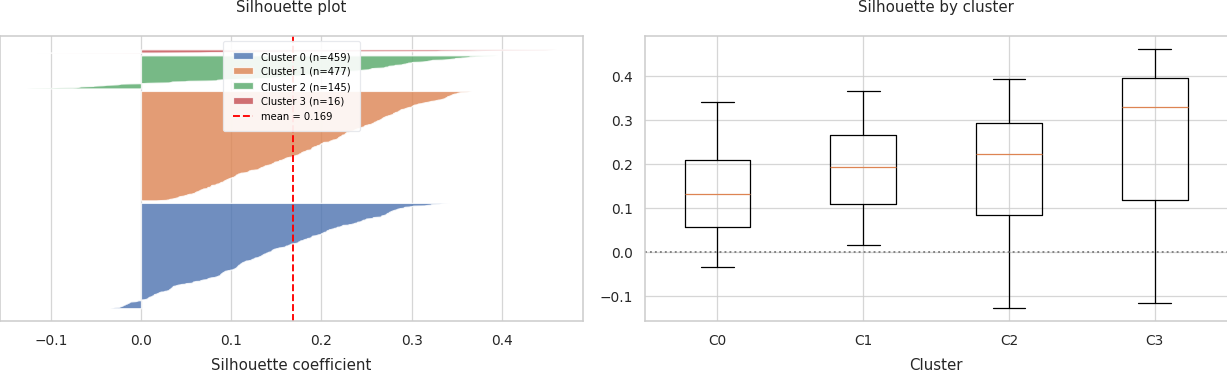

,mean_silhouette,share_negative
0,0.136,0.078
1,0.193,0.000
2,0.184,0.159
3,0.254,0.062


In [15]:
sil = silhouette_samples(Z, labels)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
y0 = 10
for c in range(K):
    v = np.sort(sil[labels == c]); ax[0].fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=.8, label=f"Cluster {c} (n={len(v)})")
    y0 += len(v) + 10
ax[0].axvline(sil.mean(), color="red", ls="--", label=f"mean = {sil.mean():.3f}")
ax[0].set_title("Silhouette plot"); ax[0].set_xlabel("Silhouette coefficient"); ax[0].set_yticks([]); ax[0].legend(fontsize=8)
ax[1].boxplot([sil[labels == c] for c in range(K)], labels=[f"C{c}" for c in range(K)]); ax[1].axhline(0, color="grey", ls=":")
ax[1].set_title("Silhouette by cluster"); ax[1].set_xlabel("Cluster")
plt.tight_layout(); plt.show()
display(pd.DataFrame({"mean_silhouette": pd.Series(sil).groupby(labels).mean(), "share_negative": pd.Series(sil < 0).groupby(labels).mean()}).round(3))

> **Insight —** Mean silhouette is highest for the tiny Cluster 3 (0.25) and lowest for Cluster 0 (0.14). Cluster 2 has the most mis-fitted bricks (15.9 % negative) and Cluster 0 about 8 %; Cluster 1 has none. The large Clusters 0 and 1 share a blurry boundary because they differ mainly in growth, not in size.

## 10. Cluster profiling
Profiles are shown in **original business units** (not standardised) so they can be read directly.

,Bricks,Avg_L12M_units,Median_L12M_units,YoY_Growth,Trend_Slope_pct_per_month,CV,Seasonality,CompA_share,CompB_share,CompC_share,Avg_pack_breadth,Pct_of_bricks,Pct_of_L12M_volume
KMeans_Cluster,,,,,,,,,,,,,
0,459,764,514,+2.7%,+0.25%,0.16,1.15,14.6%,80.4%,5.0%,6.9,41.8%,52.5%
1,477,632,461,-4.0%,+0.11%,0.15,1.12,15.4%,79.4%,5.2%,6.8,43.5%,45.1%
2,145,104,101,-2.5%,+0.15%,0.19,1.16,14.4%,84.7%,0.9%,5.3,13.2%,2.3%
3,16,33,31,-10.8%,+0.20%,0.32,1.21,5.7%,94.3%,0.0%,3.2,1.5%,0.1%


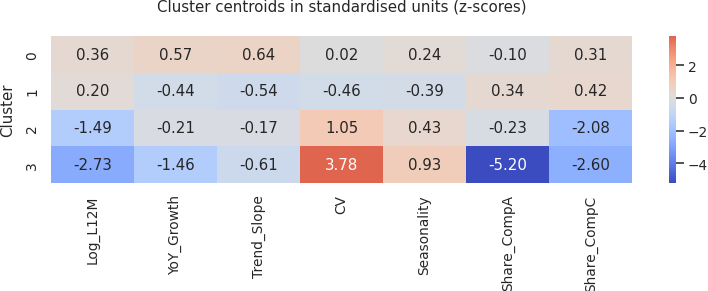

In [16]:
prof = F.groupby("KMeans_Cluster").agg(
    Bricks=("L12M", "size"), Avg_L12M_units=("L12M", "mean"), Median_L12M_units=("L12M", "median"),
    YoY_Growth=("YoY_Growth", "mean"), Trend_Slope_pct_per_month=("Trend_Slope", "mean"),
    CV=("CV", "mean"), Seasonality=("Seasonality", "mean"),
    CompA_share=("Share_CompA", "mean"), CompB_share=("Share_CompB", "mean"), CompC_share=("Share_CompC", "mean"),
    Avg_pack_breadth=("Pack_Breadth", "mean"))
prof["Pct_of_bricks"] = prof["Bricks"] / len(F)
prof["Pct_of_L12M_volume"] = F.groupby("KMeans_Cluster")["L12M"].sum() / F["L12M"].sum()
fmt = {"Avg_L12M_units": "{:,.0f}", "Median_L12M_units": "{:,.0f}", "YoY_Growth": "{:+.1%}", "Trend_Slope_pct_per_month": "{:+.2%}",
       "CV": "{:.2f}", "Seasonality": "{:.2f}", "CompA_share": "{:.1%}", "CompB_share": "{:.1%}", "CompC_share": "{:.1%}",
       "Avg_pack_breadth": "{:.1f}", "Pct_of_bricks": "{:.1%}", "Pct_of_L12M_volume": "{:.1%}"}
display(prof.style.format(fmt))

zc = Z.groupby(labels).mean()
plt.figure(figsize=(9, 3.6)); sns.heatmap(zc, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Cluster centroids in standardised units (z-scores)"); plt.ylabel("Cluster"); plt.tight_layout(); plt.show()

> **Insight —** Clusters 0 and 1 are the core (85 % of bricks, 97.6 % of volume) and differ chiefly in momentum: **C0** averages 764 units/brick and grows +2.7 %, **C1** averages 632 and declines −4.0 %. **C2** (145 bricks) is a low-volume tail (~104 units, 2.3 % of volume, almost no Company C). **C3** (16 bricks) is the micro-tail: ~33 units, 0.1 % of volume, CV 0.32 (most volatile), −10.8 % YoY, 3.2 packs on average and no Company C.

### 10.1 Visualising the clusters (PCA projection)

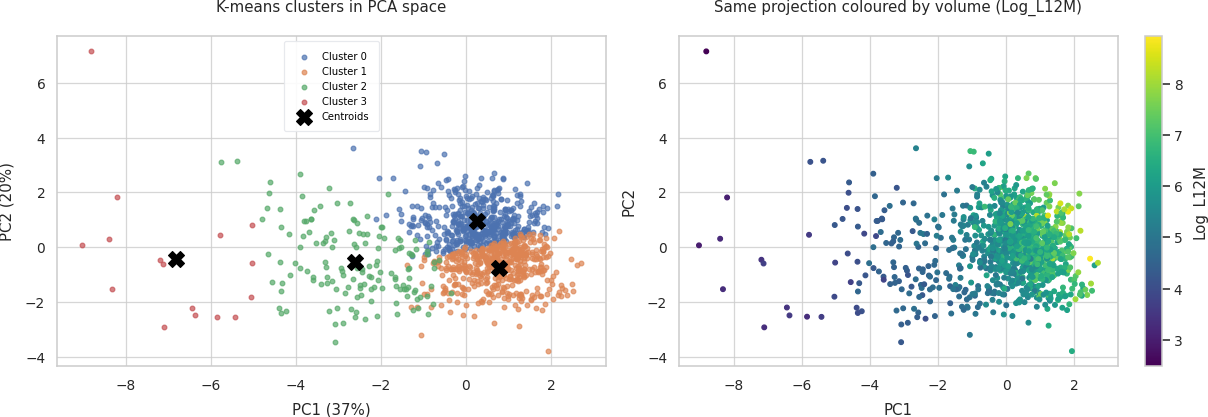

In [17]:
pca2 = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z); P = pca2.transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for c in range(K):
    ax[0].scatter(P[labels == c, 0], P[labels == c, 1], s=14, alpha=.7, label=f"Cluster {c}")
cent = pca2.transform(km.cluster_centers_[np.argsort([remap[i] for i in range(K)])])
ax[0].scatter(cent[:, 0], cent[:, 1], c="black", marker="X", s=160, label="Centroids")
ax[0].set_xlabel(f"PC1 ({pca2.explained_variance_ratio_[0]:.0%})"); ax[0].set_ylabel(f"PC2 ({pca2.explained_variance_ratio_[1]:.0%})")
ax[0].set_title("K-means clusters in PCA space"); ax[0].legend(fontsize=8)
sc = ax[1].scatter(P[:, 0], P[:, 1], c=F["Log_L12M"], cmap="viridis", s=14); plt.colorbar(sc, ax=ax[1], label="Log_L12M")
ax[1].set_title("Same projection coloured by volume (Log_L12M)"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2")
plt.tight_layout(); plt.show()

> **Insight —** PC1 separates the low-volume tail (C2, C3 on the left) from the core; C0 and C1 are split along PC2 (growth) and touch each other at the boundary. C3 sits far from everything else, including a few extreme points near PC1 ≈ −9. The right panel confirms PC1 tracks volume.

### 10.2 Cluster behaviour over time
Average monthly units per brick, indexed to the first 12-month average = 100, shows whether clusters differ in trajectory, not only level.

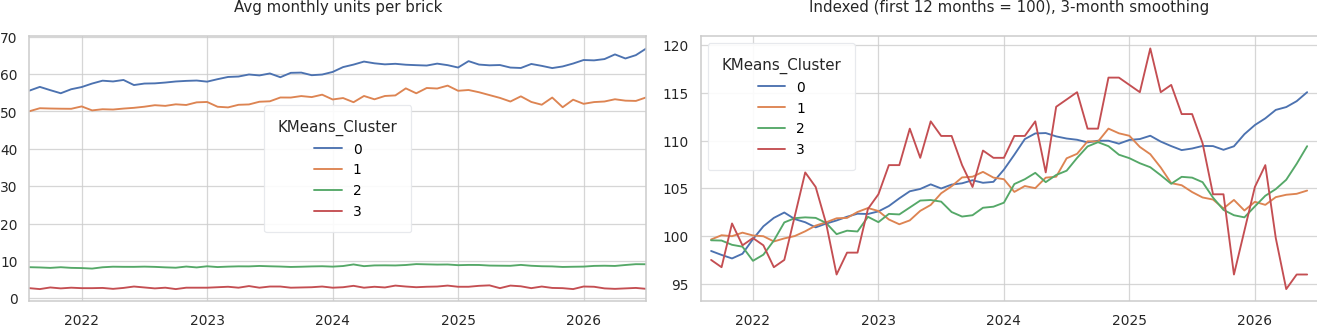

KMeans_Cluster             0      1      2      3
Index, last 12 months  112.1  103.8  105.1  100.2


In [18]:
ts = brick_month.groupby(F["KMeans_Cluster"]).mean().T
ts.index = pd.to_datetime(ts.index)
idx = ts / ts.iloc[:12].mean() * 100
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ts.plot(ax=ax[0]); ax[0].set_title("Avg monthly units per brick"); ax[0].set_xlabel("")
idx.rolling(3, center=True).mean().plot(ax=ax[1]); ax[1].set_title("Indexed (first 12 months = 100), 3-month smoothing"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()
print((idx.iloc[-12:].mean()).round(1).to_frame("Index, last 12 months").T.to_string())

> **Insight —** Per brick, C0 sells ~64 units/month vs ~54 for C1 and ≤9 for the tail. Indexed to the first 12 months, C0 ends at 112 vs 104 for C1: both rose until 2024-25, then C1 faded while C0 recovered in 2026. C3's index swings (94–120) because tiny volumes make it noisy.

## 11. External validation against State
State was **not** a model input. If clusters were just geography they would line up with state; if they are independent, the segments are portable across the country.

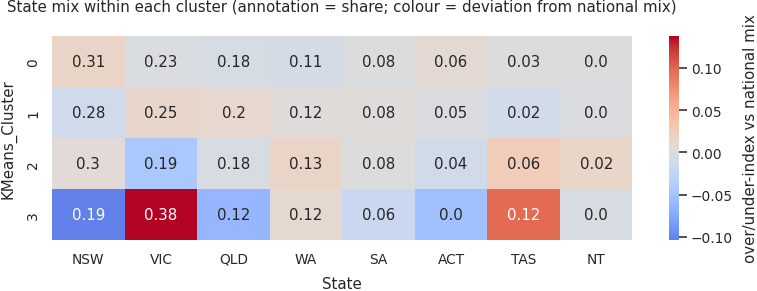

State,ACT,NSW,NT,QLD,SA,TAS,VIC,WA
KMeans_Cluster,,,,,,,,
0,28,141,2,82,37,13,107,49
1,24,133,2,94,40,8,119,57
2,6,43,3,26,12,8,28,19
3,0,3,0,2,1,2,6,2


Chi-square p-value = 0.286 | Cramer's V = 0.086 | ARI(cluster, state) = 0.003


In [19]:
ct = pd.crosstab(F["KMeans_Cluster"], F["State"])
ct_pct = ct.div(ct.sum(axis=1), axis=0)
overall = F["State"].value_counts(normalize=True)
chi2, p, dof, _ = chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
ari_state = adjusted_rand_score(F["State"], labels)
plt.figure(figsize=(9, 3.6))
sns.heatmap(ct_pct[overall.index] - overall.values, annot=ct_pct[overall.index].round(2), fmt="", cmap="coolwarm", center=0, cbar_kws={"label": "over/under-index vs national mix"})
plt.title("State mix within each cluster (annotation = share; colour = deviation from national mix)"); plt.tight_layout(); plt.show()
display(ct)
print(f"Chi-square p-value = {p:.3f} | Cramer's V = {cramers_v:.3f} | ARI(cluster, state) = {ari_state:.3f}")
metrics.update({"chi2_p_state": float(p), "cramers_v_state": float(cramers_v), "ari_vs_state": float(ari_state)})

> **Insight —** Clusters are not geographic: chi-square p = 0.29, Cramér's V = 0.09 and ARI vs State ≈ 0.003. Each segment appears in every major state in roughly the national proportions (the 16-brick C3 is too small for state-level reading), so segment rules can be applied nationally.

## 12. Segment playbook
Business labels and suggested treatment, derived from the profile above.

In [20]:
SEGMENT_NAMES = {0: "Core Growers", 1: "Core Decliners", 2: "Low-Volume Tail", 3: "Intermittent Micro-Bricks"}
F["KMeans_Segment"] = F["KMeans_Cluster"].map(SEGMENT_NAMES)
summary = F.groupby(["KMeans_Cluster", "KMeans_Segment"]).agg(Bricks=("L12M", "size"), L12M_units=("L12M", "sum"),
          Avg_units_per_brick=("L12M", "mean"), YoY=("YoY_Growth", "mean")).reset_index()
summary["Volume_share"] = summary["L12M_units"] / summary["L12M_units"].sum()
display(summary.style.format({"L12M_units": "{:,.0f}", "Avg_units_per_brick": "{:,.0f}", "YoY": "{:+.1%}", "Volume_share": "{:.1%}"}))

,KMeans_Cluster,KMeans_Segment,Bricks,L12M_units,Avg_units_per_brick,YoY,Volume_share
0,0,Core Growers,459,"350,894",764,+2.7%,52.5%
1,1,Core Decliners,477,"301,680",632,-4.0%,45.1%
2,2,Low-Volume Tail,145,"15,091",104,-2.5%,2.3%
3,3,Intermittent Micro-Bricks,16,526,33,-10.8%,0.1%


> **Insight —** Suggested use – **Core Growers** (459 bricks, 52.5 % of volume): protect and expand; **Core Decliners** (477, 45.1 %): highest-value recovery target, investigate share loss; **Low-Volume Tail** (145): low-touch/digital coverage; **Intermittent Micro-Bricks** (16): monitor only, 0.1 % of volume.

## 13. Save artefacts

In [21]:
F[["State", "L12M", "P12M"] + FEATURES + ["KMeans_Cluster", "KMeans_Segment"]].to_csv("artifacts/kmeans_labels.csv")
json.dump(metrics, open("artifacts/kmeans_metrics.json", "w"), indent=2)
print(json.dumps(metrics, indent=2))

{
  "model": "KMeans",
  "k": 4,
  "n_bricks": 1097,
  "silhouette": 0.16877223529570615,
  "davies_bouldin": 1.5676437194179462,
  "calinski_harabasz": 251.25670648405534,
  "inertia": 4544.770847001676,
  "iterations": 15,
  "bootstrap_ARI": 0.7998659579816241,
  "cluster_sizes": {
    "0": 459,
    "1": 477,
    "2": 145,
    "3": 16
  },
  "chi2_p_state": 0.2860642636338331,
  "cramers_v_state": 0.08565520629536312,
  "ari_vs_state": 0.0026252605202664245
}


> **Insight —** Labels, segment names and metrics are saved in `artifacts/` and are reused by the comparison notebook.

## 14. Conclusions & caveats
- **Result:** K-means with k = 4 gives four interpretable segments – two large core groups that differ by momentum (Growers +2.7 %, Decliners −4.0 %) and two low-volume tails (145 and 16 bricks).
- **Quality:** silhouette 0.169, Davies-Bouldin 1.57, Calinski-Harabasz 251, bootstrap ARI 0.80. Cluster structure is **weak** – the bricks form a continuum, so boundaries between C0 and C1 are soft.
- **Geography-neutral:** segments are independent of state (ARI 0.003, p = 0.29).
- **Caveats:** k = 4 was chosen on business usefulness among k ≥ 3 (k = 2 scores higher statistically); the 16-brick cluster is the least stable; the data is synthetic ("Dummy"), so real-world structure may be stronger or different.
- **Next steps:** add price/profit, brick population or prescriber counts as features, and re-test k on live data.